<a href="https://colab.research.google.com/github/yuvalzisk/robot-navigation-ml/blob/main/Robot_Navigation_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install ucimlrepo

In [5]:
import pandas as pd
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/194/wall+following+robot+navigation+data.zip"

response = requests.get(url)
response.raise_for_status()

archive = zipfile.ZipFile(io.BytesIO(response.content))

filename = next(
    name for name in archive.namelist()
    if name.endswith("sensor_readings_4.data")
)

with archive.open(filename) as file:
    df = pd.read_csv(
        file,
        header=None,
        names=["front", "left", "right", "back", "action"]
    )

print("Table shape:", df.shape)
display(df.head())

Table shape: (5456, 5)


,front,left,right,back,action
0,1.687,0.445,2.332,0.429,Slight-Right-Turn
1,1.687,0.449,2.332,0.429,Slight-Right-Turn
2,1.687,0.449,2.334,0.429,Slight-Right-Turn
3,1.687,0.449,2.334,0.429,Slight-Right-Turn
4,1.687,0.449,2.334,0.429,Slight-Right-Turn


In [4]:
df.info()

display(df.describe())

display(df["action"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5456 entries, 0 to 5455
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   front   5456 non-null   float64
 1   left    5456 non-null   float64
 2   right   5456 non-null   float64
 3   back    5456 non-null   float64
 4   action  5456 non-null   object 
dtypes: float64(4), object(1)
memory usage: 213.3+ KB


,front,left,right,back
count,5456.000000,5456.000000,5456.000000,5456.000000
mean,1.290307,0.681269,1.881819,1.273689
std,0.626700,0.342594,0.562533,0.821750
min,0.495000,0.340000,0.836000,0.367000
25%,0.826000,0.495000,1.472000,0.788000
50%,1.089500,0.612000,1.753000,1.066500
75%,1.519500,0.753000,2.139000,1.400500
max,5.000000,5.000000,5.000000,5.000000


,count
action,
Move-Forward,2205
Sharp-Right-Turn,2097
Slight-Right-Turn,826
Slight-Left-Turn,328


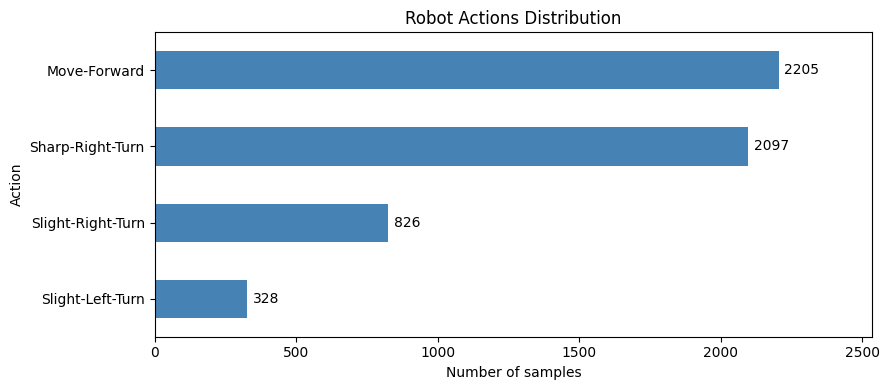

In [6]:
import matplotlib.pyplot as plt

action_counts = df["action"].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))

action_counts.plot.barh(ax=ax, color="steelblue")

ax.set_title("Robot Actions Distribution")
ax.set_xlabel("Number of samples")
ax.set_ylabel("Action")

ax.bar_label(ax.containers[0], padding=4)

ax.invert_yaxis()
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

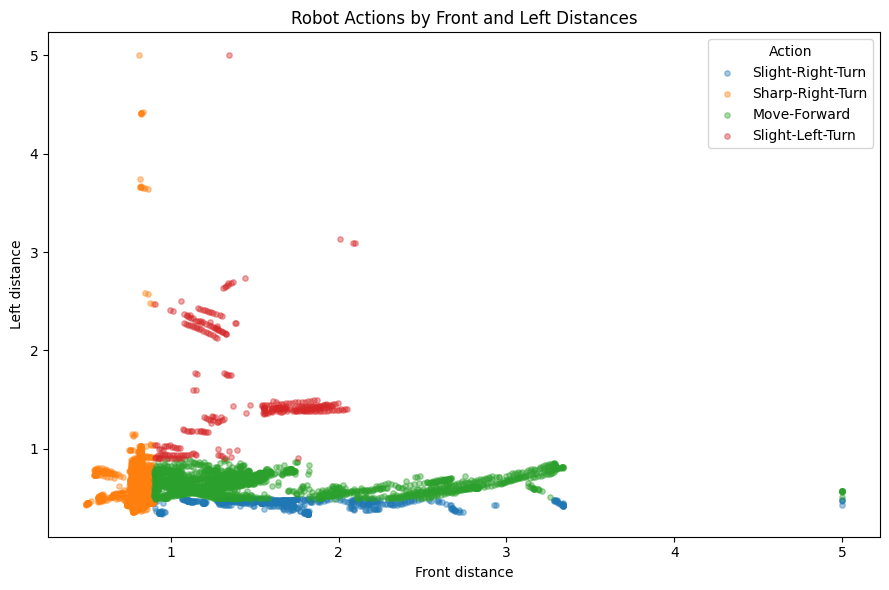

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))

for action in df["action"].unique():
    subset = df[df["action"] == action]

    ax.scatter(
        subset["front"],
        subset["left"],
        label=action,
        alpha=0.4,
        s=15
    )

ax.set_title("Robot Actions by Front and Left Distances")
ax.set_xlabel("Front distance")
ax.set_ylabel("Left distance")
ax.legend(title="Action")

plt.tight_layout()
plt.show()

In [9]:

X = df[["front", "left", "right", "back"]]

y = df["action"]

display(X.head())
display(y.head())

print("X shape:", X.shape)
print("y shape:", y.shape)

,front,left,right,back
0,1.687,0.445,2.332,0.429
1,1.687,0.449,2.332,0.429
2,1.687,0.449,2.334,0.429
3,1.687,0.449,2.334,0.429
4,1.687,0.449,2.334,0.429


,action
0,Slight-Right-Turn
1,Slight-Right-Turn
2,Slight-Right-Turn
3,Slight-Right-Turn
4,Slight-Right-Turn


X shape: (5456, 4)
y shape: (5456,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (4364, 4)
Test: (1092, 4)


In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

model = DecisionTreeClassifier(max_depth=3, random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.2%}")

Test accuracy: 100.00%


In [13]:
print("Tree depth:", model.get_depth())
print("Test samples:", len(y_test))
print("Mistakes:", (y_pred != y_test).sum())

Tree depth: 3
Test samples: 1092
Mistakes: 0


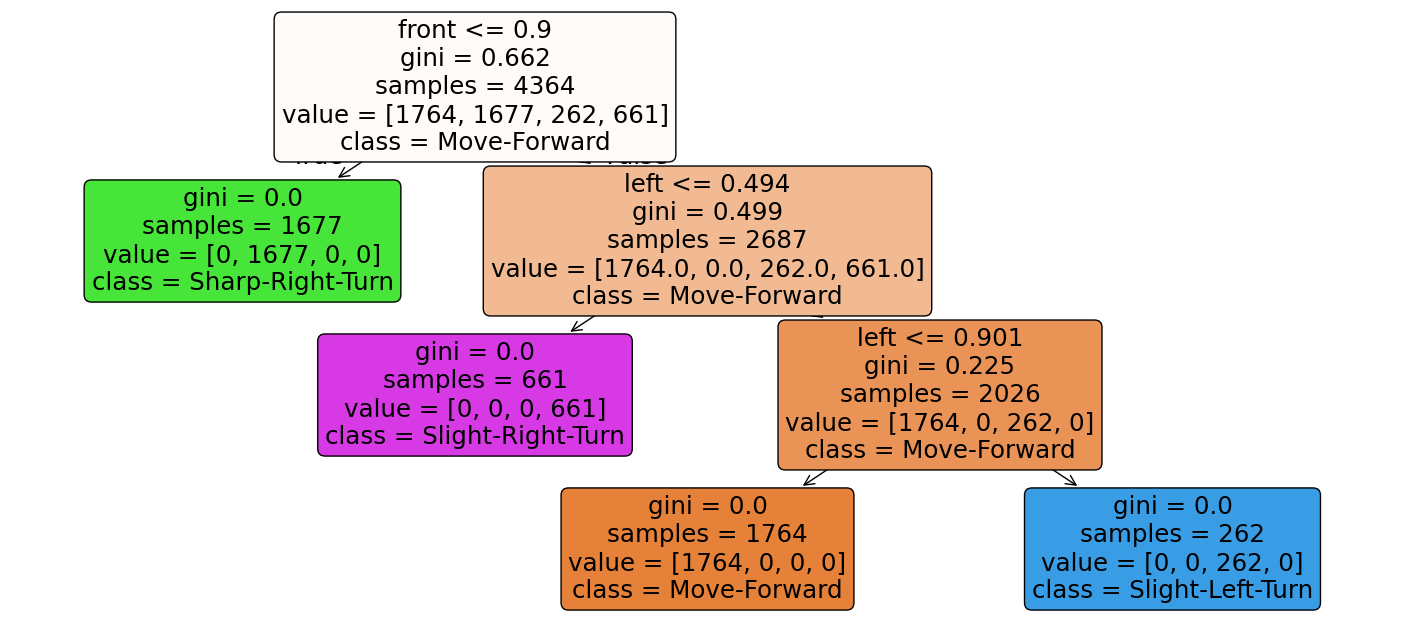

In [14]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 8))

plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=model.classes_.tolist(),
    filled=True,
    rounded=True,
    precision=3
)

plt.show()

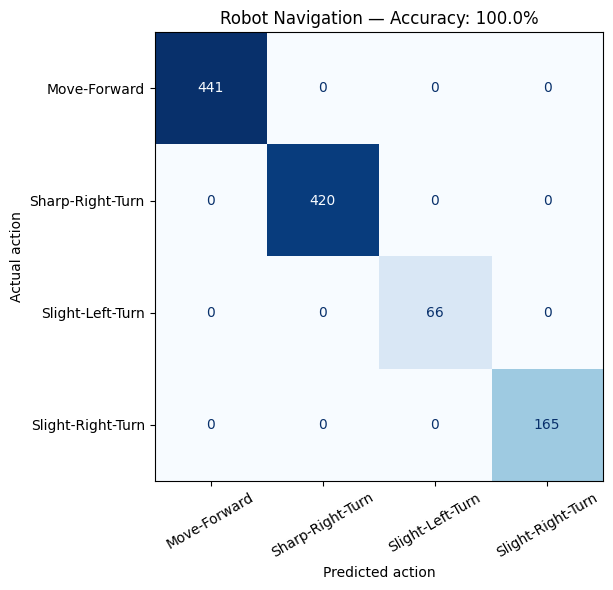

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=model.classes_,
    cmap="Blues",
    values_format="d",
    xticks_rotation=30,
    colorbar=False,
    ax=ax
)

ax.set_title(f"Robot Navigation — Accuracy: {accuracy:.1%}")
ax.set_xlabel("Predicted action")
ax.set_ylabel("Actual action")

plt.tight_layout()
plt.show()